In [1]:
import marimo as mo

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
from kaggle_api import fetch_dataset

df_train, df_test = fetch_dataset()

✅ data loaded!


# model overview

- type - GAM logistic regression
- predictor selection method - manual

In [4]:
cols_categorical = "x4 x5 x10 Y".split()

df_train["Y"] = df_train["Y"].astype("category")

for df in (df_train, df_test):
    for _col in cols_categorical[:-1]:
        df[_col] = df[_col].astype("category")

    df["x1a"] = (df.x1 >= 0).astype(np.int8).astype("category")

In [5]:
df_train.iloc[:, df_train.columns != "Y"]

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x1a
ID,,,,,,,,,,,
1,0.0173,-1.0968,0.3725,0,2,0.0547,1.5471,-0.3371,-0.4551,1,1
2,-0.2145,0.5228,0.2572,0,0,0.0489,-1.9378,0.2004,-0.7517,2,0
3,-1.4413,0.1400,-0.1907,1,0,-2.2845,-0.0585,-0.0021,-0.5917,0,0
4,-0.5113,-0.5586,-0.4460,1,0,1.4341,0.7005,-2.6717,-0.7258,0,0
5,-0.8045,-0.7673,-1.2111,0,0,0.2241,-0.2277,-1.7400,-0.2095,3,0
...,...,...,...,...,...,...,...,...,...,...,...
14996,0.5005,0.5796,2.6121,0,0,1.3226,-0.0109,1.1438,1.8113,1,1
14997,-0.0028,-0.7421,0.3539,1,1,-0.8141,-1.6515,-0.2005,-0.7705,3,0
14998,0.2976,1.5863,0.0946,0,1,-1.2523,0.5718,-1.4961,-0.5201,2,1


In [6]:
from pygam import LogisticGAM, f, s

gam = LogisticGAM(
    s(1 - 1) + s(2 - 1) + s(3 - 1) + f(4 - 1) + f(5 - 1) + s(6 - 1) + s(7 - 1) + s(8 - 1) + s(9 - 1) + f(10 - 1) + f(11 - 1)
).fit(df_train.iloc[:, df_train.columns != "Y"], df_train.Y)

In [7]:
gam.summary()

LogisticGAM                                                                                               
=============================================== ==========================================================
Distribution:                      BinomialDist Effective DoF:                                     91.0959
Link Function:                        LogitLink Log Likelihood:                                 -7887.8358
Number of Samples:                        15000 AIC:                                            15957.8635
                                                AICc:                                           15959.0138
                                                UBRE:                                               3.0687
                                                Scale:                                                 1.0
                                                Pseudo R-Squared:                                   0.1106
Feature Function                  Lam

/tmp/nix-shell.aplRml/ipykernel_95070/3358381670.py:1: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  gam.summary()


now we remove the insignificant ones ($x_{10}, x_1, x_8, x_9$):

TODO use forward-backward-lasso to select parameters instead

In [18]:
prediction = gam.predict(df_test).astype(np.int64)

prediction_probs = pd.Series(prediction, index=df_test.index)
prediction_probs.describe()

count    10000.000000
mean         0.090400
std          0.286768
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
dtype: float64

# model assessment

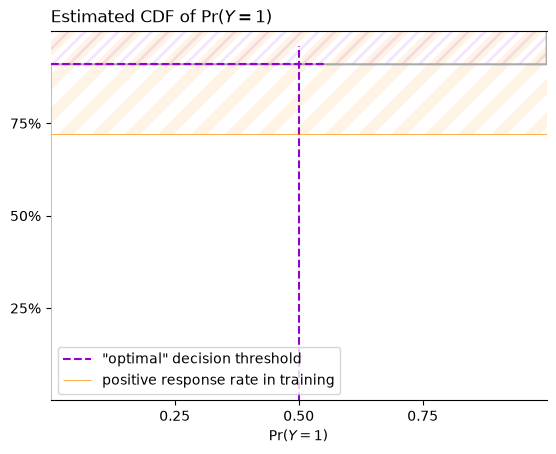

In [19]:
import threshold as th

pos_prediction_count, threshold = th.estimate_optimal_threshold(prediction_probs)

mo.output.append(pos_prediction_count)
mo.output.append(threshold)

mo.output.append(
    th.plot_probs(
        probs=prediction_probs,
        expt_prob=np.mean(df_train.Y.astype(np.int64)),
        threshold=threshold,
        pos_pred_count=pos_prediction_count,
    )
)

<Axes: title={'left': 'Comparison of F-scores'}>

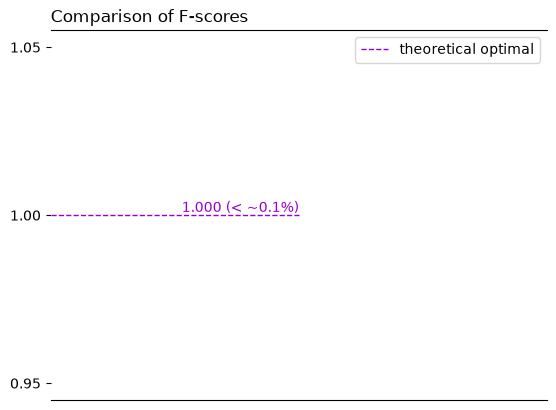

In [10]:
rng = np.random.default_rng(1)

th.plot_f_scores(
    empiricals=th.sample_probable_f_scores(
        rng, 1000, prediction_probs, pos_prediction_count
    ),
    calculated=2 * threshold,
    reported=None,
)

# make submission

In [11]:
predictions = prediction_probs.sort_values(ascending=False)
predictions.iloc[0:pos_prediction_count] = 1
predictions.iloc[pos_prediction_count:] = 0
predictions = predictions.astype(np.int8).sort_index()

predictions

ID
15001    0
15002    0
15003    0
15004    0
15005    0
        ..
24996    0
24997    1
24998    0
24999    0
25000    0
Length: 10000, dtype: int8

In [12]:
import os
import os.path
import pathlib

notebook_path = os.environ.get("JPY_SESSION_NAME")
submission_filepath = pathlib.Path(
    f"./submissions/{os.path.splitext(os.path.basename(notebook_path))[0]}.csv"
)
print(f"saving submission file to {submission_filepath}")
predictions.to_csv(submission_filepath)

saving submission file to submissions/model4_gam_binomial.csv
